# Heavy tails

Some variables are made of many small values and a few enormous ones. Gold grades, insurance claims,
river discharges in flood and the size of wildfires all have heavy tails, where the largest datum can be
hundreds of times the median. An estimate built from averages lets those few values spread, while
kriging can even dig holes below the smallest datum around them. Here we see both on simulated fields
with a very heavy tail, and read what the ensemble's members offer instead.

## Learning goals

- Why a heavy tail breaks the mean of the members, and why their median holds.
- Why an ensemble map never leaves the range of the data, while kriging does.
- How every map understates the largest values, and by how much.
- How these hold over several fields, not only one.

*How should an ensemble be read when a few values dominate?*

## The idea

A **heavy tail** puts real probability on huge values. In a Pareto law of exponent close to one, the
mean barely exists, so an average over a few hundred data swings with the one or two largest. Any
estimate that averages inherits that swing.

The ensemble has two defences. Its averaging decoders use **convex weights**, positive and summing to
one, so every member, and every map built from them, stays between the smallest and the largest
datum. And its members form a law at each location, so a robust reading such as the **median** can
replace the mean. Kriging's weights can be negative, which lets its map fall below the smallest datum,
typically in a ring around a very large value, a *negative halo*. The book behind Spatialize treats this
case among its situations, a Pareto field where the median of the members does better than their
mean.

## Step by step

### A field with a heavy tail

The field is a Voronoi block-mark field on the unit square, 45 cells each with one value drawn from a
Pareto law of exponent 1.05, all at least 1. We draw 350 samples at random. The map uses a logarithmic
colour scale, since a linear one would show only the largest cell.

data from 1.01 to 37.5, median 2.12, mean 5.48


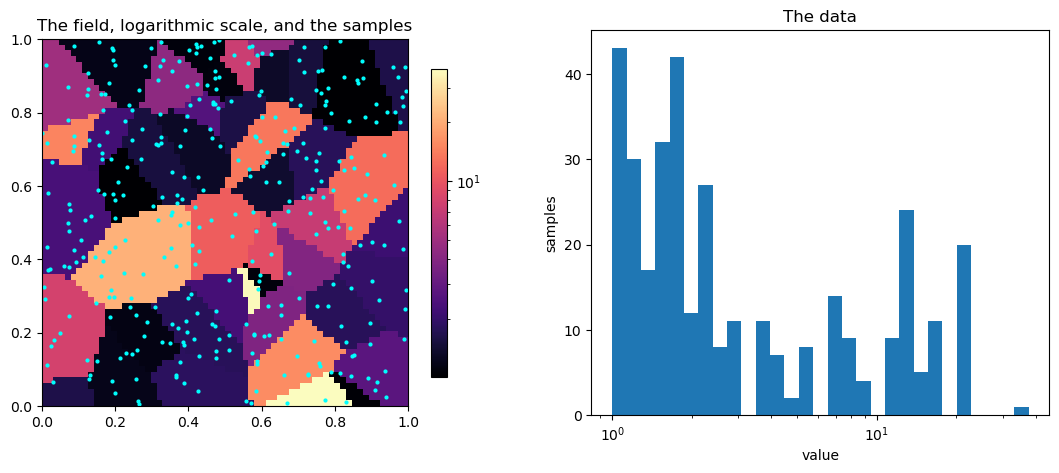

In [1]:
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from scipy.optimize import curve_fit
from pykrige.ok import OrdinaryKriging

import spatialize
from spatialize.gs.esi import esi_nongriddata, esi_pareto_hparams_search
import spatialize.gs.esi.aggfunction as af
import spatialize.gs.esi.scorefunction as sf

spatialize.session.set(empty_cells="coarsen", progress=False)
warnings.filterwarnings("ignore", module="pykrige")

m = 64
grid = (np.arange(m) + 0.5) / m
xi = np.stack(np.meshgrid(grid, grid), -1).reshape(-1, 2)          # maps are [y, x]

def heavy_field(seed, n_cells=45, n_samples=350):
    rng = np.random.default_rng(seed)
    nuclei = rng.random((n_cells, 2))
    marks = rng.pareto(1.05, n_cells) + 1.0
    value = lambda x: marks[np.argmin(((x[:, None, :] - nuclei[None]) ** 2).sum(-1), axis=1)]
    points = rng.random((n_samples, 2))
    return points, value(points), value(xi)

points, values, truth = heavy_field(0)
print(f"data from {values.min():.2f} to {values.max():.1f}, median {np.median(values):.2f}, "
      f"mean {values.mean():.2f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
im = axes[0].imshow(truth.reshape(m, m), origin="lower", extent=(0, 1, 0, 1), cmap="magma", norm=LogNorm())
axes[0].scatter(points[:, 0], points[:, 1], s=4, c="cyan")
axes[0].set_title("The field, logarithmic scale, and the samples")
fig.colorbar(im, ax=axes[0], shrink=0.8)
axes[1].hist(values, bins=np.logspace(0, np.log10(values.max()), 30), color="C0")
axes[1].set_xscale("log"); axes[1].set_xlabel("value"); axes[1].set_ylabel("samples")
axes[1].set_title("The data")
plt.show()

Most samples lie between 1 and 3, while a few reach twenty and one nearly forty. The mean of the data,
5.5, sits far above their median, 2.1, pulled up by those few.

### Mean against median

The Pareto search chooses the granularity for adaptive IDW. With it we run three decoders, IDW, adaptive
IDW and the weighted draw of IDW, and read each ensemble twice, by the mean of its members and by their
median (`re_estimate(af.median)`).

In [2]:
alpha = esi_pareto_hparams_search(points, values, local_interpolator="adaptiveidw", n_partitions=[100],
                                  alpha=[0.7, 0.8, 0.9, 0.95], k="loo", scoring=sf.mae,
                                  seed=0).best_result(strategy="knee")["alpha"]
print(f"alpha at the knee {alpha}")

decoders = {"IDW": dict(local_interpolator="idw", exponent=2.0),
            "adaptive IDW": dict(local_interpolator="adaptiveidw"),
            "weighted draw of IDW": dict(local_interpolator="wdraw_idw", exponent=2.0)}
maps, rows = {}, {}
for name, decoder in decoders.items():
    result = esi_nongriddata(points, values, xi, alpha=alpha, n_partitions=200, seed=0, **decoder)
    maps[f"{name}, mean"] = result.estimation()
    maps[f"{name}, median"] = result.re_estimate(af.median)
    rows[name] = {"MAE, mean": np.mean(np.abs(maps[f"{name}, mean"] - truth)),
                  "MAE, median": np.mean(np.abs(maps[f"{name}, median"] - truth))}
pd.DataFrame(rows).T.round(3)

alpha at the knee 0.9


,"MAE, mean","MAE, median"
IDW,2.132,2.071
adaptive IDW,1.483,1.146
weighted draw of IDW,2.140,1.149


For every decoder the median of the members comes closer to the truth than their mean, slightly for
IDW, by a quarter for adaptive IDW and by almost half for the weighted draw. The weighted draw changes
most, since its members are data values. Their median is a typical datum of the neighbourhood, while
their mean drags in the rare large ones.

### Below the smallest datum

Ordinary kriging, with a spherical variogram fitted to the experimental variogram of the data in the
usual way, gives the reference. Every value of the field is at least 1, so any estimate below the smallest datum is wrong by construction, a negative one impossible.

In [3]:
def spherical(h, c0, c, a):
    return c0 + c * np.where(h < a, 1.5 * h / a - 0.5 * (h / a) ** 3, 1.0)

def kriging(points, values):
    i, j = np.triu_indices(len(points), 1)
    dist = np.hypot(*(points[i] - points[j]).T)
    half_sq = 0.5 * (values[i] - values[j]) ** 2
    bins = np.digitize(dist, np.linspace(0, 0.6, 16))
    h = np.array([dist[bins == b].mean() for b in range(1, 16)])
    g = np.array([half_sq[bins == b].mean() for b in range(1, 16)])
    (c0, c, a), _ = curve_fit(spherical, h, g, p0=[0.1 * g.max(), g.max(), 0.2],
                              bounds=([0, 1e-6, 0.01], [np.inf, np.inf, 2]))
    ok = OrdinaryKriging(points[:, 0], points[:, 1], values, variogram_model="spherical",
                         variogram_parameters={"sill": c0 + c, "range": a, "nugget": c0})
    return ok.execute("points", xi[:, 0], xi[:, 1])[0].data

maps["ordinary kriging"] = kriging(points, values)
below = pd.DataFrame({name: {"smallest value": z.min(), "share below the smallest datum": np.mean(z < values.min()),
                             "share negative": np.mean(z < 0)}
                      for name, z in maps.items() if name.endswith("mean") or name == "ordinary kriging"}).T
below.round(3)

,smallest value,share below the smallest datum,share negative
"IDW, mean",1.014,0.000,0.000
"adaptive IDW, mean",1.013,0.000,0.000
"weighted draw of IDW, mean",1.013,0.000,0.000
ordinary kriging,-0.308,0.055,0.002


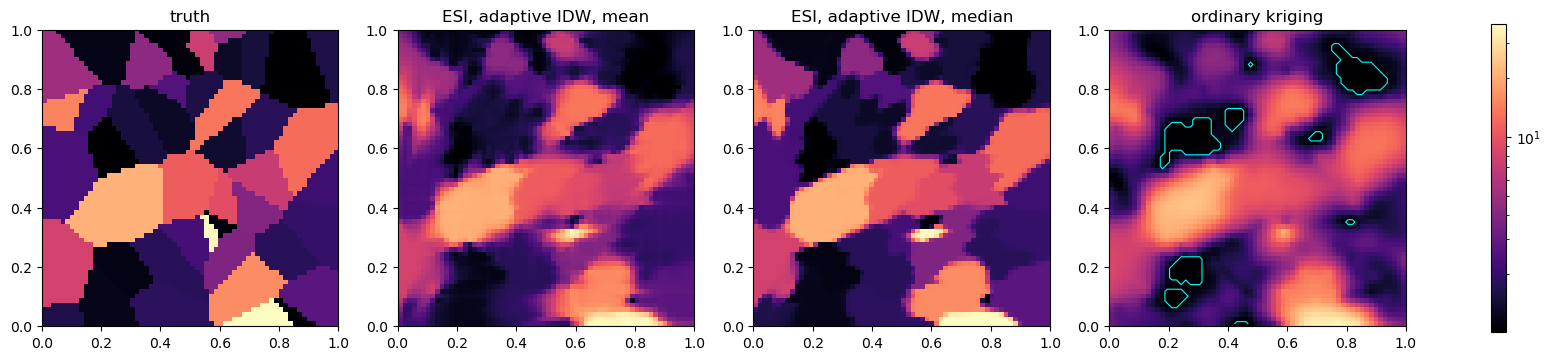

In [4]:
shown = {"truth": truth, "ESI, adaptive IDW, mean": maps["adaptive IDW, mean"],
         "ESI, adaptive IDW, median": maps["adaptive IDW, median"], "ordinary kriging": maps["ordinary kriging"]}
fig, axes = plt.subplots(1, 4, figsize=(22, 5))
norm = LogNorm(vmin=values.min(), vmax=truth.max())
for ax, (title, z) in zip(axes, shown.items()):
    im = ax.imshow(np.clip(z, values.min(), None).reshape(m, m), origin="lower", extent=(0, 1, 0, 1), cmap="magma", norm=norm)
    if title == "ordinary kriging":
        ax.contour(grid, grid, (z < values.min()).reshape(m, m).astype(float), levels=[0.5], colors="cyan", linewidths=0.8)
    ax.set_title(title)
fig.colorbar(im, ax=axes, shrink=0.8)
plt.show()

The median keeps the cells of the truth, their straight edges and their levels, while the mean blends
neighbouring cells, the large values spreading into the small ones around them. Kriging draws rounded
blobs, smoother than either, and goes below the smallest datum inside the cyan outlines, between the
large cells.

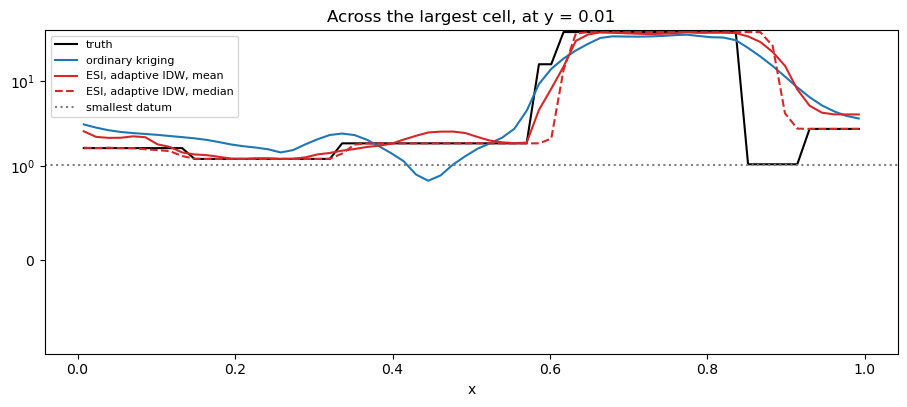

In [5]:
row = np.unravel_index(np.argmax(truth), (m, m))[0]
fig, ax = plt.subplots(figsize=(11, 4.2))
ax.plot(grid, truth.reshape(m, m)[row], color="black", lw=1.5, label="truth")
ax.plot(grid, maps["ordinary kriging"].reshape(m, m)[row], color="C0", label="ordinary kriging")
ax.plot(grid, maps["adaptive IDW, mean"].reshape(m, m)[row], color="C3", label="ESI, adaptive IDW, mean")
ax.plot(grid, maps["adaptive IDW, median"].reshape(m, m)[row], color="C3", ls="--", label="ESI, adaptive IDW, median")
ax.axhline(values.min(), color="0.5", ls=":", label="smallest datum")
ax.set_yscale("symlog", linthresh=1.0)
ax.set_xlabel("x"); ax.set_title(f"Across the largest cell, at y = {grid[row]:.2f}")
ax.legend(fontsize=8)
plt.show()

No ensemble map goes below the smallest datum, since convex weights keep every member within the data.
Kriging goes below it on 5.5 % of the grid, and below zero at a few cells, down to −0.31. Across the
largest cell, kriging dips below the smallest datum at x ≈ 0.45, before the rise to the large cell, a dip
of the kind negative kriging weights produce. The median of the ensemble follows the steps of the truth,
while its mean smooths them.

### The largest values

Every map understates the largest values, which no average can reach. The signed error on the cells
whose true value lies in the top tenth of the field measures by how much.

In [6]:
top = truth >= np.quantile(truth, 0.9)
pd.Series({name: np.mean(z[top] - truth[top]) for name, z in maps.items()},
          name="mean signed error on the top tenth").round(2).to_frame()

,mean signed error on the top tenth
"IDW, mean",-6.32
"IDW, median",-6.40
"adaptive IDW, mean",-3.86
"adaptive IDW, median",-3.31
"weighted draw of IDW, mean",-6.29
"weighted draw of IDW, median",-4.80
ordinary kriging,-4.42


Every map understates the top tenth. Adaptive IDW understates it least, by 3.3 with the median of its
members, kriging by 4.4, and IDW by more than 6, mean or median.

### Five fields

A heavy tail makes every number above depend on the one or two largest values of the field, so we
repeat the comparison on five fields, each with its own draw.

In [7]:
rows = {}
for seed in range(5):
    p, v, t = heavy_field(seed)
    a = esi_pareto_hparams_search(p, v, local_interpolator="adaptiveidw", n_partitions=[100],
                                  alpha=[0.7, 0.8, 0.9, 0.95], k="loo", scoring=sf.mae,
                                  seed=0).best_result(strategy="knee")["alpha"]
    r = esi_nongriddata(p, v, xi, local_interpolator="adaptiveidw", alpha=a, n_partitions=200, seed=0)
    k = kriging(p, v)
    rows[f"field {seed}"] = {"largest datum": v.max(),
                             "MAE, ESI mean": np.mean(np.abs(r.estimation() - t)),
                             "MAE, ESI median": np.mean(np.abs(r.re_estimate(af.median) - t)),
                             "MAE, kriging": np.mean(np.abs(k - t)),
                             "kriging below the smallest datum": np.mean(k < v.min()),
                             "ESI below the smallest datum": np.mean(r.estimation() < v.min())}
pd.DataFrame(rows).T.round(3)

,largest datum,"MAE, ESI mean","MAE, ESI median","MAE, kriging",kriging below the smallest datum,ESI below the smallest datum
field 0,37.463,1.483,1.146,1.917,0.055,0.0
field 1,70.348,2.357,1.746,2.843,0.144,0.0
field 2,163.115,3.382,2.787,5.309,0.195,0.0
field 3,77.715,2.698,2.262,2.931,0.108,0.0
field 4,215.142,2.242,1.396,3.324,0.133,0.0


On every field the ensemble's median has the lowest error, its mean comes second and kriging last, its
error up to almost twice the median's. Kriging goes below the smallest datum on 5 % to 20 % of the grid,
the ensemble never.

## Pitfalls

- **The mean of the members as the map.** Under a heavy tail a few large members pull the mean far from
  where most of them lie, so the large values spread into their neighbours. Read the median of the
  members, or a quantile, instead.
- **A granularity chosen by a squared error.** The squared error of the cross-validation is dominated by
  the few largest cells, so the search tunes the ensemble to them. Search with the absolute error, as
  here.
- **The top of the tail.** No member exceeds the largest datum, so no map built from them does. The top tenth comes out understated, while a value larger than any sample cannot appear
  at all.
- **One large datum deciding the map.** The cells around the largest datum change from partition to
  partition, so with few partitions its spread depends on the seed. Use a few hundred partitions and
  compare seeds before trusting the map near the largest data.

## Try it yourself

1. Raise the exponent of the Pareto law to 3, a lighter tail, and watch the gap between mean and median
   close.
2. Read the 25th and 75th percentiles of the members (`af.Percentile`) as a band around the median.
3. Krige the logarithm of the data and transform back, and compare its error and its halos.

## Next

- *Rain, an atom at zero*, for a law with a point mass at zero.
- *The probabilistic decoders*, for the drawing decoders and their laws.
- *A non-stationary field*, for a law that changes across the domain.
- The documentation's [Decoders](https://spatialize.readthedocs.io/en/latest/theory/decoders.html) (theory).